# Exploring Unsupervised Classification

## Objective
Explore whether K-means clustering can separate plant material from
the background in GoPro photographs.

We will start by grouping pixels using their red, green, and blue
(RGB) values, then inspect which clusters contain plant material,
background, or a mixture of both.

K-means does not know what a plant is. It groups pixels with similar
feature values; we interpret those groups afterward.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans

## Load project data

Use the same project folders and data tables as the previous notebook.
The morphology table links each sample and branch to its reference
and branch photographs.

In [2]:
# Project paths.
project_folder = Path(r"C:\Users\mguar\Documents\OEAS805\FinalProject")
raw_folder = project_folder / "DATA" / "raw"
image_folder = raw_folder / "GoProImages_Susquehanna_Milfoil"

# Load the data tables.
morphmeasures = pd.read_excel(
    raw_folder / "Morphmeasures_Susquehanna_milfoil.xlsx"
)
gopro_metadata = pd.read_excel(
    raw_folder / "GoPro_Metadata_Susquehanna_milfoil.xlsx"
)

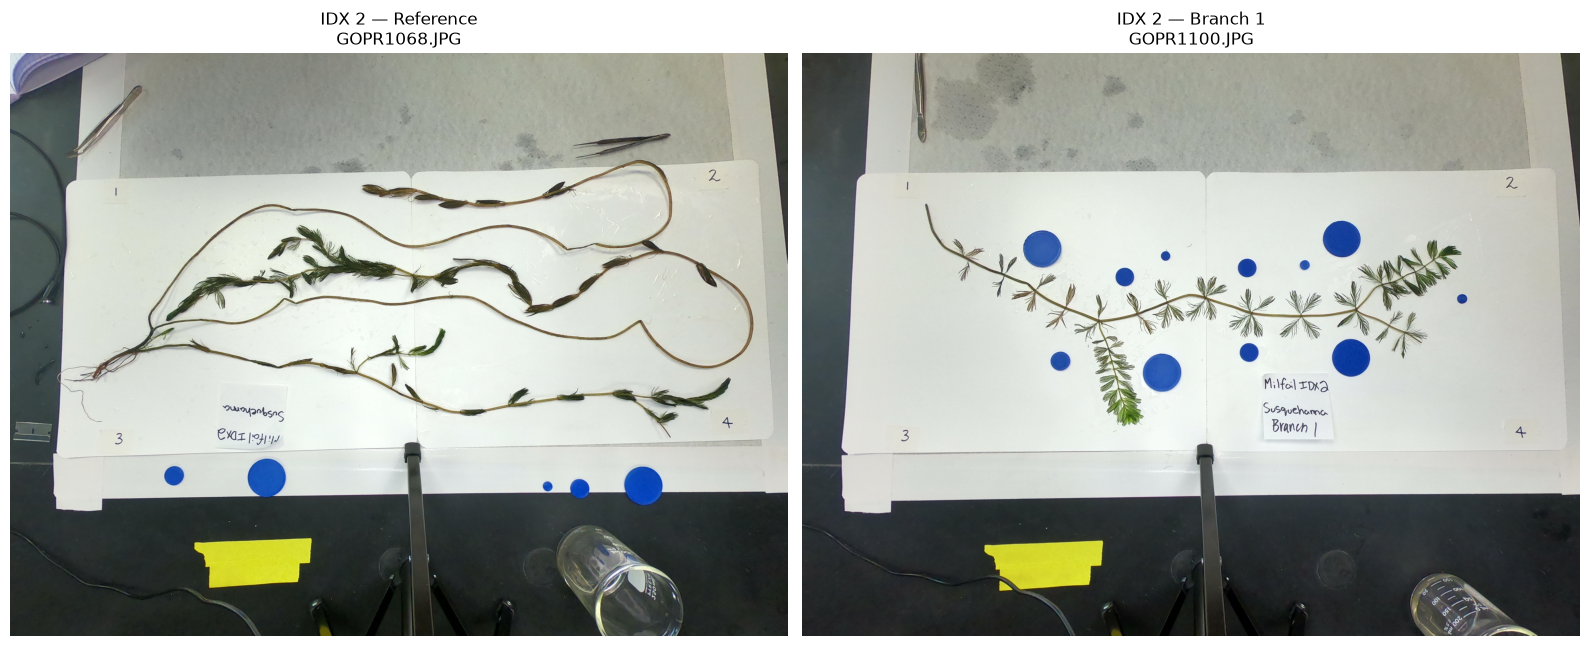

In [4]:
# Select the sample and branch.
idx = 2
branch_num = 1

row = morphmeasures.loc[
    (morphmeasures["IDX"] == idx)
    & (morphmeasures["BRANCHNUM"] == branch_num)
].iloc[0]

# Match image names with or without file extensions.
image_lookup = {
    path.stem.upper(): path
    for path in image_folder.iterdir()
    if path.is_file()
    and path.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff"}
}

reference_path = image_lookup[
    Path(str(row["REFERENCE"]).strip()).stem.upper()
]
branch_path = image_lookup[
    Path(str(row["BRANCH"]).strip()).stem.upper()
]

# Load both images as RGB arrays.
with Image.open(reference_path) as img:
    reference_rgb = np.array(img.convert("RGB"))

with Image.open(branch_path) as img:
    branch_rgb = np.array(img.convert("RGB"))

# Display reference and branch photographs.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(reference_rgb)
axes[0].set_title(f"IDX {idx} — Reference\n{reference_path.name}")

axes[1].imshow(branch_rgb)
axes[1].set_title(
    f"IDX {idx} — Branch {branch_num}\n{branch_path.name}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

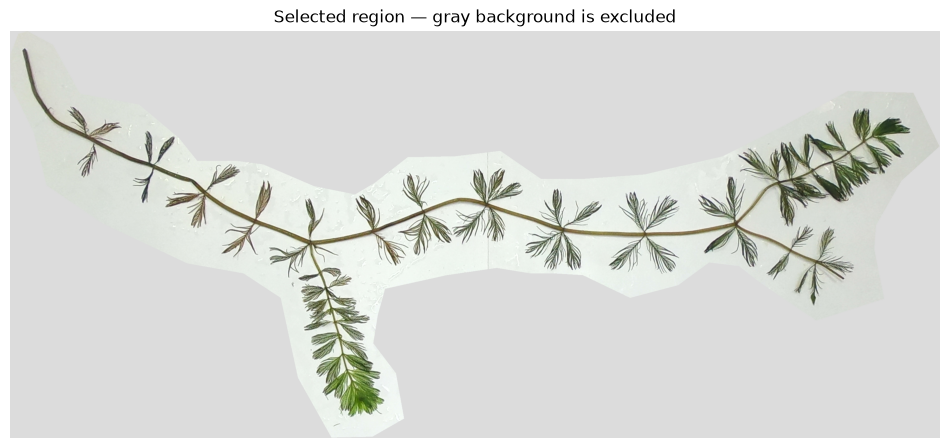

In [5]:
# Enable an interactive plot in a separate window.
%matplotlib tk

# Click around the region to keep.
# Press Enter when finished.
fig, ax = plt.subplots(figsize=(14, 9))

ax.imshow(branch_rgb)
ax.set_title("Click around the region to keep — press Enter to finish")

crop_vertices = np.array(plt.ginput(n=-1, timeout=0))
plt.close(fig)

if len(crop_vertices) < 3:
    raise ValueError("Select at least three points to define the crop.")

# Identify original-image pixels inside the polygon.
from matplotlib.path import Path as PolygonPath

height, width = branch_rgb.shape[:2]
yy, xx = np.indices((height, width))

crop_mask = PolygonPath(crop_vertices).contains_points(
    np.column_stack([xx.ravel(), yy.ravel()])
).reshape(height, width)

# Trim the image and mask to the polygon's bounding rectangle.
x0 = max(0, int(np.floor(crop_vertices[:, 0].min())))
x1 = min(width, int(np.ceil(crop_vertices[:, 0].max())) + 1)
y0 = max(0, int(np.floor(crop_vertices[:, 1].min())))
y1 = min(height, int(np.ceil(crop_vertices[:, 1].max())) + 1)

cropped_rgb = branch_rgb[y0:y1, x0:x1].copy()
cropped_mask = crop_mask[y0:y1, x0:x1]

# Return subsequent figures to notebook output.
%matplotlib inline

# Preview the crop; gray pixels are outside the polygon.
crop_preview = np.full_like(cropped_rgb, 220)
crop_preview[cropped_mask] = cropped_rgb[cropped_mask]

plt.figure(figsize=(12, 7))
plt.imshow(crop_preview)
plt.title("Selected region — gray background is excluded")
plt.axis("off")
plt.show()

# Two cluster classification

The idea here is that there is 

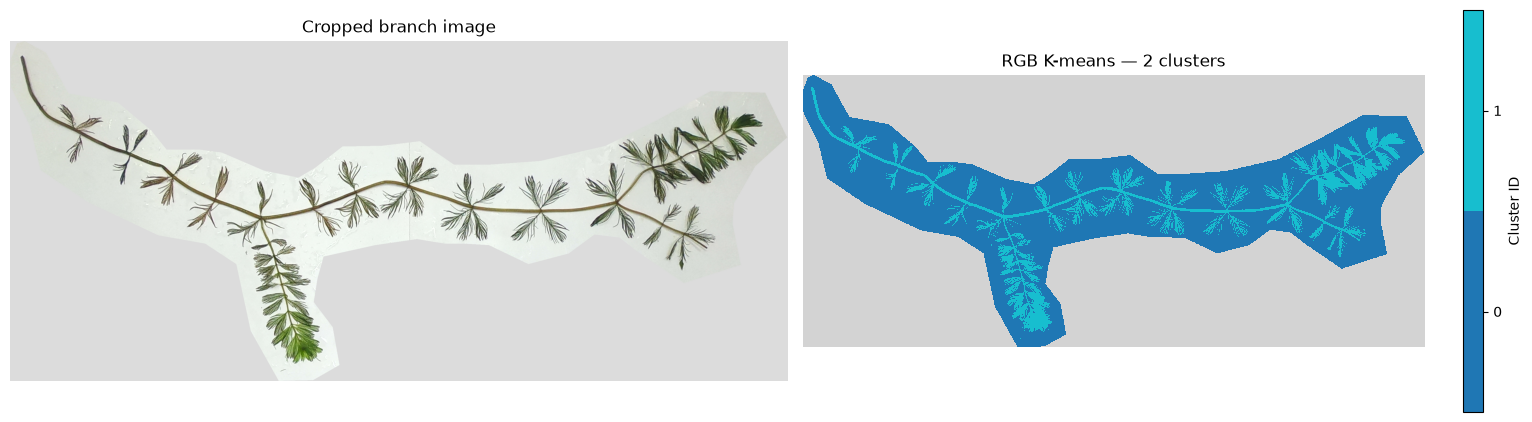

In [6]:
k = 2

# Only pixels INSIDE the polygon enter K-means.
pixels = cropped_rgb[cropped_mask].astype(np.float32) / 255.0

rng = np.random.default_rng(42)
sample_indices = rng.choice(
    len(pixels),
    size=min(50_000, len(pixels)),
    replace=False
)

model = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)
model.fit(pixels[sample_indices])

# Use -1 outside the polygon; these pixels were not clustered.
cluster_map = np.full(cropped_mask.shape, -1, dtype=int)
cluster_map[cropped_mask] = model.predict(pixels)

# Display the cropped image and cluster assignments.
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(crop_preview)
axes[0].set_title("Cropped branch image")

cmap = plt.get_cmap("tab10", k).copy()
cmap.set_bad("lightgray")

cluster_plot = axes[1].imshow(
    np.ma.masked_where(~cropped_mask, cluster_map),
    cmap=cmap,
    vmin=-0.5,
    vmax=k - 0.5,
    interpolation="nearest"
)
axes[1].set_title(f"RGB K-means — {k} clusters")

fig.colorbar(
    cluster_plot,
    ax=axes[1],
    ticks=range(k),
    label="Cluster ID",
    shrink=0.6
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

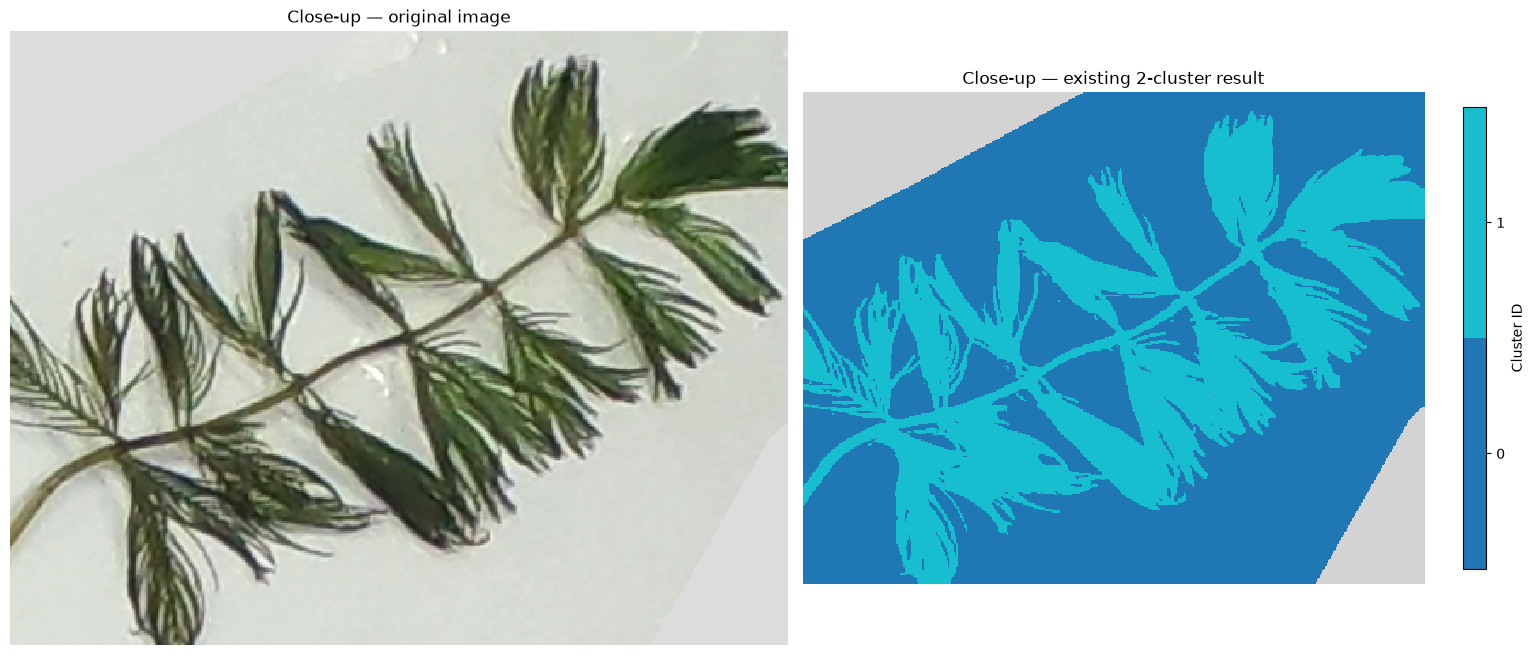

In [7]:
# Select a closer view from the existing crop.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title("Click TWO opposite corners around the region to inspect")

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Convert the selected coordinates into rectangle bounds.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

# Extract matching portions of the image, mask, and cluster map.
zoom_rgb = crop_preview[zy0:zy1, zx0:zx1]
zoom_mask = cropped_mask[zy0:zy1, zx0:zx1]
zoom_clusters = cluster_map[zy0:zy1, zx0:zx1]

%matplotlib inline

# Display original pixels beside their existing cluster assignments.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(zoom_rgb, interpolation="nearest")
axes[0].set_title("Close-up — original image")

zoom_cmap = plt.get_cmap("tab10", k).copy()
zoom_cmap.set_bad("lightgray")

im = axes[1].imshow(
    np.ma.masked_where(~zoom_mask, zoom_clusters),
    cmap=zoom_cmap,
    vmin=-0.5,
    vmax=k - 0.5,
    interpolation="nearest"
)
axes[1].set_title(f"Close-up — existing {k}-cluster result")

fig.colorbar(
    im,
    ax=axes[1],
    ticks=range(k),
    label="Cluster ID",
    shrink=0.6
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

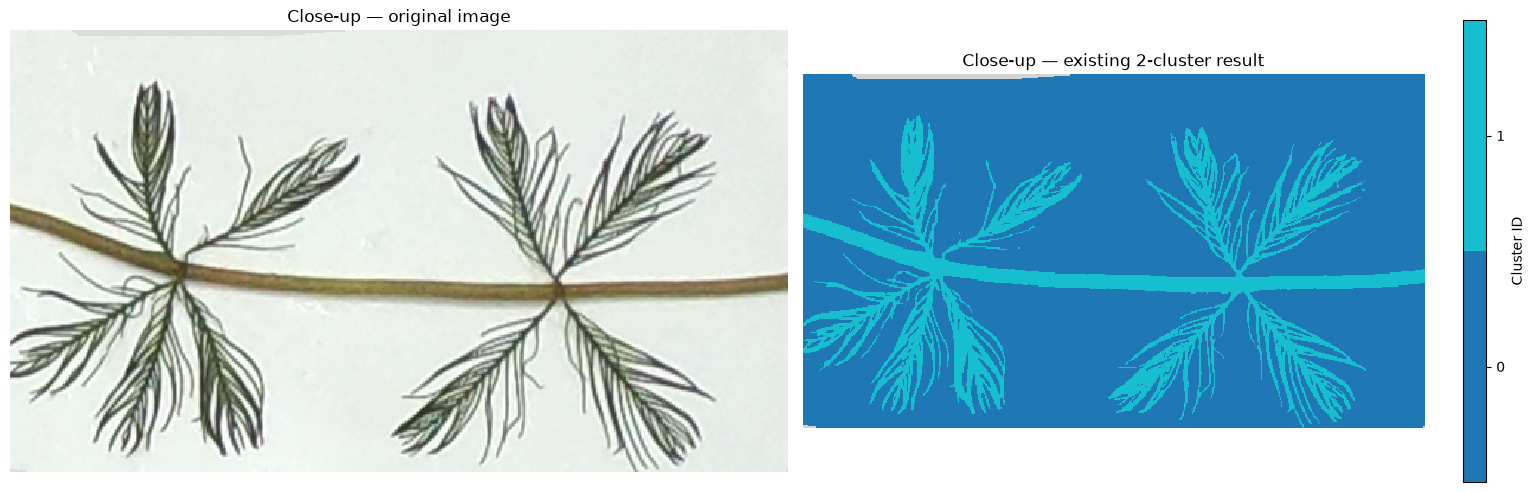

In [8]:
# Select a closer view from the existing crop.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title("Click TWO opposite corners around the region to inspect")

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Convert the selected coordinates into rectangle bounds.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

# Extract matching portions of the image, mask, and cluster map.
zoom_rgb = crop_preview[zy0:zy1, zx0:zx1]
zoom_mask = cropped_mask[zy0:zy1, zx0:zx1]
zoom_clusters = cluster_map[zy0:zy1, zx0:zx1]

%matplotlib inline

# Display original pixels beside their existing cluster assignments.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(zoom_rgb, interpolation="nearest")
axes[0].set_title("Close-up — original image")

zoom_cmap = plt.get_cmap("tab10", k).copy()
zoom_cmap.set_bad("lightgray")

im = axes[1].imshow(
    np.ma.masked_where(~zoom_mask, zoom_clusters),
    cmap=zoom_cmap,
    vmin=-0.5,
    vmax=k - 0.5,
    interpolation="nearest"
)
axes[1].set_title(f"Close-up — existing {k}-cluster result")

fig.colorbar(
    im,
    ax=axes[1],
    ticks=range(k),
    label="Cluster ID",
    shrink=0.6
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

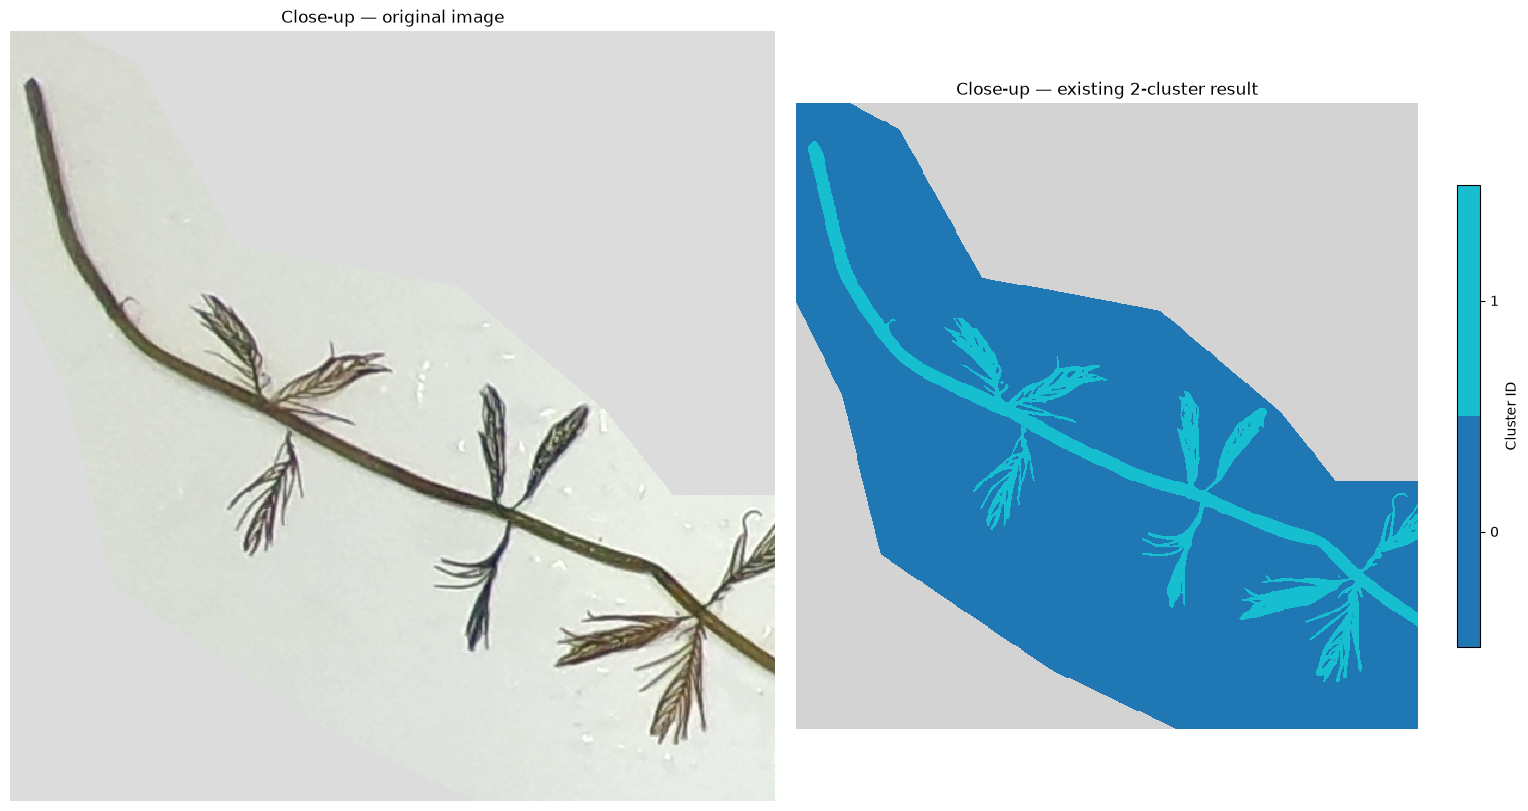

In [9]:
# Select a closer view from the existing crop.
%matplotlib tk

fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(crop_preview)
ax.set_title("Click TWO opposite corners around the region to inspect")

corners = np.array(plt.ginput(n=2, timeout=0))
plt.close(fig)

if len(corners) != 2:
    raise ValueError("Select two opposite corners.")

# Convert the selected coordinates into rectangle bounds.
h, w = cropped_rgb.shape[:2]

zx0 = max(0, int(np.floor(corners[:, 0].min())))
zx1 = min(w, int(np.ceil(corners[:, 0].max())) + 1)
zy0 = max(0, int(np.floor(corners[:, 1].min())))
zy1 = min(h, int(np.ceil(corners[:, 1].max())) + 1)

if zx1 <= zx0 or zy1 <= zy0:
    raise ValueError("Select a rectangle inside the image.")

# Extract matching portions of the image, mask, and cluster map.
zoom_rgb = crop_preview[zy0:zy1, zx0:zx1]
zoom_mask = cropped_mask[zy0:zy1, zx0:zx1]
zoom_clusters = cluster_map[zy0:zy1, zx0:zx1]

%matplotlib inline

# Display original pixels beside their existing cluster assignments.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].imshow(zoom_rgb, interpolation="nearest")
axes[0].set_title("Close-up — original image")

zoom_cmap = plt.get_cmap("tab10", k).copy()
zoom_cmap.set_bad("lightgray")

im = axes[1].imshow(
    np.ma.masked_where(~zoom_mask, zoom_clusters),
    cmap=zoom_cmap,
    vmin=-0.5,
    vmax=k - 0.5,
    interpolation="nearest"
)
axes[1].set_title(f"Close-up — existing {k}-cluster result")

fig.colorbar(
    im,
    ax=axes[1],
    ticks=range(k),
    label="Cluster ID",
    shrink=0.6
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()